# Лабораторная работа 1. Основы статистических вычислений на Python

**Цель:** приобрести навыки работы с NumPy, SciPy и Matplotlib для статистических расчётов, генерации случайных данных, визуализации распределений и проверки закона больших чисел (ЗБЧ).

**Выбранные распределения:**

| Распределение | Тип | Параметры |
|---|---|---|
| Экспоненциальное | непрерывное | λ = 1 (scale = 1/λ = 1) |
| Пуассона | дискретное | λ = 3 |

Распределения выбраны так, чтобы в работе было одно непрерывное и одно дискретное: для непрерывного строится гистограмма с плотностью, для дискретного — столбчатая диаграмма с функцией вероятности. Оба распределения несимметричны, поэтому асимметрия и эксцесс у них отличны от нуля, что делает проверку этих статистик содержательной.

In [ ]:
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt

np.random.seed(42)         
plt.rcParams['figure.dpi'] = 110

N = 500                     
LAM_EXP = 1.0               
LAM_POIS = 3.0             

## 1. Генерация выборок

`np.random.exponential` принимает не λ, а **scale = 1/λ** (среднее значение). При λ = 1 они совпадают, но об этом важно помнить.

In [2]:
x_exp = np.random.exponential(scale=1/LAM_EXP, size=N)
x_pois = np.random.poisson(lam=LAM_POIS, size=N)

print('Экспоненциальная, первые 10 значений:', np.round(x_exp[:10], 3))
print('Пуассон, первые 10 значений:        ', x_pois[:10])

Экспоненциальная, первые 10 значений: [0.469 3.01  1.317 0.913 0.17  0.17  0.06  2.011 0.919 1.231]
Пуассон, первые 10 значений:         [5 8 0 3 6 1 9 3 3 6]


## 2. Собственные функции для выборочных характеристик

По заданию все статистики реализуются вручную, без готовых `np.mean`, `np.var` и т.д. Разрешены только базовые операции: `np.sum`, `np.sort`, `np.sqrt`, `len`.

Формулы:

* среднее: $\bar x = \frac{1}{n}\sum x_i$
* несмещённая дисперсия: $s^2 = \frac{1}{n-1}\sum (x_i-\bar x)^2$
* стандартное отклонение: $s=\sqrt{s^2}$
* квантиль уровня $p$ — линейная интерполяция между соседними порядковыми статистиками (тот же метод `linear`, что у `np.percentile` по умолчанию): позиция $h=(n-1)p$, $Q(p)=x_{(\lfloor h\rfloor)} + (h-\lfloor h\rfloor)\,(x_{(\lfloor h\rfloor+1)}-x_{(\lfloor h\rfloor)})$
* медиана — квантиль уровня 0.5
* асимметрия: $S=\frac{1}{n}\sum\left(\frac{x_i-\bar x}{\sigma}\right)^3$
* эксцесс: $K=\frac{1}{n}\sum\left(\frac{x_i-\bar x}{\sigma}\right)^4-3$

**Замечание про σ в асимметрии и эксцессе.** `scipy.stats.skew` и `scipy.stats.kurtosis` (с `bias=True` по умолчанию) делят на смещённое отклонение $\sigma=\sqrt{\frac1n\sum(x_i-\bar x)^2}$. Чтобы сравнение со scipy было корректным, функции по умолчанию используют именно его (`ddof=0`). Параметр `ddof=1` даёт вариант с несмещённым $s$, как записано в методичке; при n = 500 разница между ними меньше 0.5%.

In [3]:
def my_mean(x):
    x = np.asarray(x, dtype=float)
    return np.sum(x) / len(x)

def my_var(x, ddof=1):
    """Дисперсия. ddof=1 — несмещённая (делим на n-1), ddof=0 — смещённая (на n)."""
    x = np.asarray(x, dtype=float)
    m = my_mean(x)
    return np.sum((x - m) ** 2) / (len(x) - ddof)

def my_std(x, ddof=1):
    return np.sqrt(my_var(x, ddof))

def my_quantile(x, p):
    """Квантиль уровня p (0..1), линейная интерполяция как в np.percentile."""
    xs = np.sort(np.asarray(x, dtype=float))
    h = (len(xs) - 1) * p
    lo = int(h)                       # floor для h >= 0
    hi = min(lo + 1, len(xs) - 1)
    return xs[lo] + (h - lo) * (xs[hi] - xs[lo])

def my_median(x):
    return my_quantile(x, 0.5)

def my_skew(x, ddof=0):
    x = np.asarray(x, dtype=float)
    z = (x - my_mean(x)) / my_std(x, ddof)
    return np.sum(z ** 3) / len(x)

def my_kurtosis(x, ddof=0):
    """Избыточный эксцесс (минус 3), как scipy.stats.kurtosis по умолчанию."""
    x = np.asarray(x, dtype=float)
    z = (x - my_mean(x)) / my_std(x, ddof)
    return np.sum(z ** 4) / len(x) - 3

def my_stats(x):
    return {
        'Среднее': my_mean(x),
        'Дисперсия': my_var(x),
        'Ст. отклонение': my_std(x),
        'Медиана': my_median(x),
        'Q1 (25%)': my_quantile(x, 0.25),
        'Q3 (75%)': my_quantile(x, 0.75),
        'Асимметрия': my_skew(x),
        'Эксцесс': my_kurtosis(x),
    }

### 2.1. Проверка собственных функций против встроенных

Для дисперсии и стандартного отклонения у numpy передаём `ddof=1`, так как по умолчанию `np.var` и `np.std` считают смещённую оценку.

In [4]:
def builtin_stats(x):
    return {
        'Среднее': np.mean(x),
        'Дисперсия': np.var(x, ddof=1),
        'Ст. отклонение': np.std(x, ddof=1),
        'Медиана': np.median(x),
        'Q1 (25%)': np.percentile(x, 25),
        'Q3 (75%)': np.percentile(x, 75),
        'Асимметрия': stats.skew(x),
        'Эксцесс': stats.kurtosis(x),
    }

for name, x in [('Экспоненциальное', x_exp), ('Пуассона', x_pois)]:
    mine, ref = my_stats(x), builtin_stats(x)
    print(f'--- {name} ---')
    print(f'{"Статистика":<16}{"Своя функция":>14}{"numpy/scipy":>14}{"|разница|":>12}')
    for k in mine:
        print(f'{k:<16}{mine[k]:>14.6f}{ref[k]:>14.6f}{abs(mine[k]-ref[k]):>12.1e}')
    assert all(np.isclose(mine[k], ref[k]) for k in mine)
    print('Все значения совпадают (np.isclose = True)\n')

--- Экспоненциальное ---
Статистика        Своя функция   numpy/scipy   |разница|
Среднее               1.004309      1.004309     0.0e+00
Дисперсия             0.948717      0.948717     0.0e+00
Ст. отклонение        0.974021      0.974021     0.0e+00
Медиана               0.719830      0.719830     0.0e+00
Q1 (25%)              0.276123      0.276123     0.0e+00
Q3 (75%)              1.411107      1.411107     0.0e+00
Асимметрия            1.440901      1.440901     4.4e-16
Эксцесс               1.854397      1.854397     1.8e-15
Все значения совпадают (np.isclose = True)

--- Пуассона ---
Статистика        Своя функция   numpy/scipy   |разница|
Среднее               2.956000      2.956000     0.0e+00
Дисперсия             3.052168      3.052168     0.0e+00
Ст. отклонение        1.747046      1.747046     0.0e+00
Медиана               3.000000      3.000000     0.0e+00
Q1 (25%)              2.000000      2.000000     0.0e+00
Q3 (75%)              4.000000      4.000000     0.0e+00
Ас

## 3. Сравнение выборочных и теоретических характеристик

Теоретические значения:

| Характеристика | Экспоненциальное (λ) | при λ = 1 | Пуассона (λ) | при λ = 3 |
|---|---|---|---|---|
| Матожидание | 1/λ | 1 | λ | 3 |
| Дисперсия | 1/λ² | 1 | λ | 3 |
| Ст. отклонение | 1/λ | 1 | √λ | 1.732 |
| Медиана | ln2/λ | 0.693 | ≈ λ + 1/3 − 0.02/λ, целое | 3 |
| Q1 | −ln(0.75)/λ | 0.288 | из функции распределения | 2 |
| Q3 | ln4/λ | 1.386 | из функции распределения | 4 |
| Асимметрия | 2 | 2 | 1/√λ | 0.577 |
| Эксцесс (избыточный) | 6 | 6 | 1/λ | 0.333 |

Числа ниже берутся из `scipy.stats` (`mean`, `var`, `ppf`, `stats(moments='sk')`), чтобы не вводить их вручную.

In [5]:
def theory(dist):
    m, v, s, k = dist.stats(moments='mvsk')
    return {
        'Среднее': float(m), 'Дисперсия': float(v), 'Ст. отклонение': float(np.sqrt(v)),
        'Медиана': float(dist.median()),
        'Q1 (25%)': float(dist.ppf(0.25)), 'Q3 (75%)': float(dist.ppf(0.75)),
        'Асимметрия': float(s), 'Эксцесс': float(k),
    }

exp_dist = stats.expon(scale=1/LAM_EXP)
pois_dist = stats.poisson(mu=LAM_POIS)

def print_table(name, x, dist):
    emp, th = my_stats(x), theory(dist)
    print(f'=== {name} (n = {len(x)}) ===')
    print(f'{"Статистика":<16}{"Выборка":>10}{"Теория":>10}{"Отклонение":>12}')
    for k in emp:
        print(f'{k:<16}{emp[k]:>10.4f}{th[k]:>10.4f}{emp[k]-th[k]:>12.4f}')
    print()
    return emp, th

emp_exp, th_exp = print_table('Экспоненциальное, λ = 1', x_exp, exp_dist)
emp_pois, th_pois = print_table('Пуассона, λ = 3', x_pois, pois_dist)

=== Экспоненциальное, λ = 1 (n = 500) ===
Статистика         Выборка    Теория  Отклонение
Среднее             1.0043    1.0000      0.0043
Дисперсия           0.9487    1.0000     -0.0513
Ст. отклонение      0.9740    1.0000     -0.0260
Медиана             0.7198    0.6931      0.0267
Q1 (25%)            0.2761    0.2877     -0.0116
Q3 (75%)            1.4111    1.3863      0.0248
Асимметрия          1.4409    2.0000     -0.5591
Эксцесс             1.8544    6.0000     -4.1456

=== Пуассона, λ = 3 (n = 500) ===
Статистика         Выборка    Теория  Отклонение
Среднее             2.9560    3.0000     -0.0440
Дисперсия           3.0522    3.0000      0.0522
Ст. отклонение      1.7470    1.7321      0.0150
Медиана             3.0000    3.0000      0.0000
Q1 (25%)            2.0000    2.0000      0.0000
Q3 (75%)            4.0000    4.0000      0.0000
Асимметрия          0.5798    0.5774      0.0024
Эксцесс             0.0241    0.3333     -0.3092



**Комментарий.** Среднее, дисперсия, медиана и квартили близки к теоретическим. Сильнее всего отклоняются асимметрия и особенно эксцесс: они зависят от 3-й и 4-й степеней отклонений, поэтому несколько крупных значений в правом хвосте сильно меняют результат. Для экспоненциального распределения выборочный эксцесс заметно отличается от 6, и это ожидаемо при n = 500.

Квартили Пуассона целые, потому что распределение дискретное: выборочный квантиль почти всегда попадает на одно из повторяющихся целых значений.

## 4. Визуализация

### 4.1. Экспоненциальное распределение: гистограмма и плотность

`density=True` нормирует гистограмму так, что её площадь равна 1. Только тогда её можно сравнивать с плотностью $f(x)=\lambda e^{-\lambda x}$.

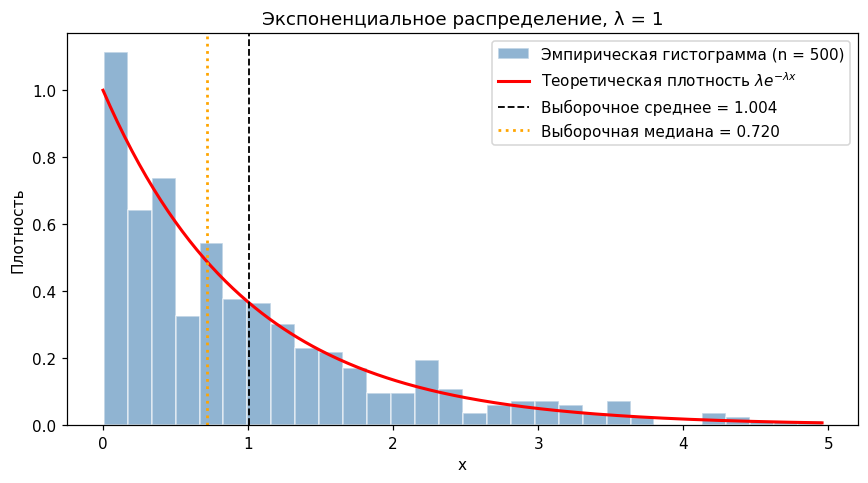

In [6]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(x_exp, bins=30, density=True, alpha=0.6, color='steelblue', edgecolor='white',
        label='Эмпирическая гистограмма (n = 500)')
grid = np.linspace(0, x_exp.max(), 300)
ax.plot(grid, exp_dist.pdf(grid), 'r-', lw=2, label='Теоретическая плотность $\\lambda e^{-\\lambda x}$')
ax.axvline(my_mean(x_exp), color='k', ls='--', lw=1.2, label=f'Выборочное среднее = {my_mean(x_exp):.3f}')
ax.axvline(my_median(x_exp), color='orange', ls=':', lw=1.8, label=f'Выборочная медиана = {my_median(x_exp):.3f}')
ax.set_xlabel('x')
ax.set_ylabel('Плотность')
ax.set_title('Экспоненциальное распределение, λ = 1')
ax.legend()
plt.tight_layout()
plt.savefig('fig1_exponential.png', dpi=130)
plt.show()

Гистограмма убывает так же, как теоретическая кривая. Медиана лежит левее среднего: это признак правосторонней (положительной) асимметрии, длинный правый хвост «тянет» среднее вправо.

### 4.2. Распределение Пуассона: столбчатая диаграмма и функция вероятности

Для дискретного распределения гистограмма с произвольными бинами неудобна, поэтому строим bar plot относительных частот $\hat p_k = n_k/n$ для каждого целого $k$ и накладываем теоретические вероятности $P(X=k)=\frac{\lambda^k e^{-\lambda}}{k!}$. Сумма относительных частот равна 1, то есть это и есть нормировка на «плотность».

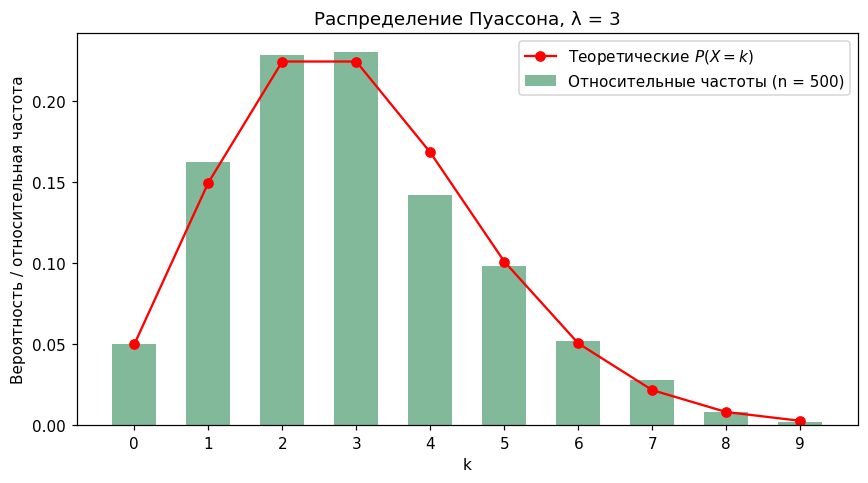

  k   частота    P(X=k)
  0     0.050     0.050
  1     0.162     0.149
  2     0.228     0.224
  3     0.230     0.224
  4     0.142     0.168
  5     0.098     0.101
  6     0.052     0.050
  7     0.028     0.022
  8     0.008     0.008
  9     0.002     0.003


In [7]:
k_vals = np.arange(0, x_pois.max() + 1)
counts = np.array([np.sum(x_pois == k) for k in k_vals])
rel_freq = counts / N

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(k_vals, rel_freq, width=0.6, alpha=0.6, color='seagreen', label='Относительные частоты (n = 500)')
ax.plot(k_vals, pois_dist.pmf(k_vals), 'ro-', lw=1.5, ms=6, label='Теоретические $P(X=k)$')
ax.set_xticks(k_vals)
ax.set_xlabel('k')
ax.set_ylabel('Вероятность / относительная частота')
ax.set_title('Распределение Пуассона, λ = 3')
ax.legend()
plt.tight_layout()
plt.savefig('fig2_poisson.png', dpi=130)
plt.show()

print(f'{"k":>3}{"частота":>10}{"P(X=k)":>10}')
for k, f, p in zip(k_vals, rel_freq, pois_dist.pmf(k_vals)):
    print(f'{k:>3}{f:>10.3f}{p:>10.3f}')

## 5. Имитационное моделирование: закон больших чисел

Распределение для эксперимента — экспоненциальное (λ = 1, μ = 1). Оно сильно асимметрично, поэтому на нём хорошо видно, что сходимость среднего не требует симметрии.

Эксперимент: для n = 1, 11, 21, …, 991 (шаг 10) повторяем 100 раз: генерируем выборку размера n и считаем её среднее. Получаем матрицу 100 × 100: строки — повторения, столбцы — значения n. Каждая строка — одна «траектория» среднего.

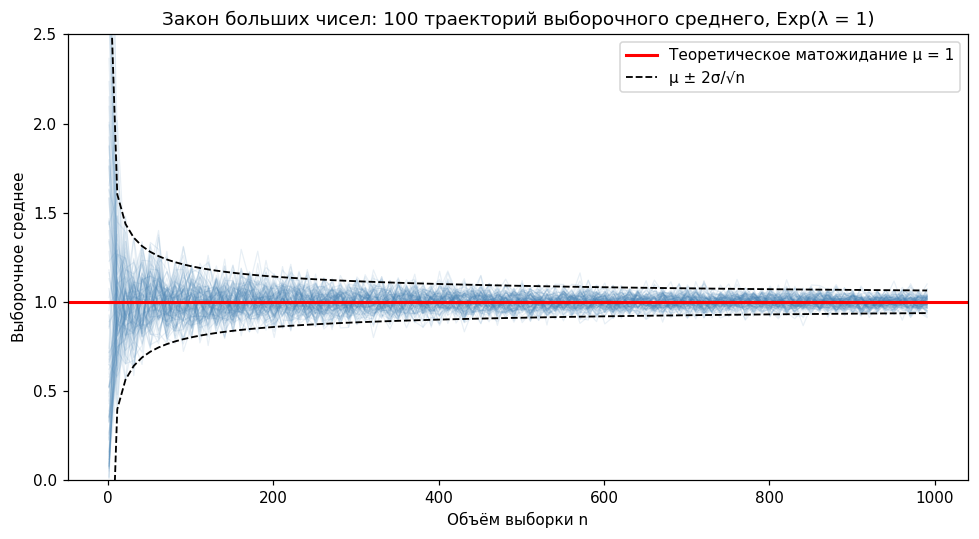

In [8]:
ns = np.arange(1, 1001, 10)     # 1, 11, ..., 991 -> 100 значений
R = 100                          # число повторений
MU = 1 / LAM_EXP                 # теоретическое матожидание
SIGMA = 1 / LAM_EXP              # теоретическое ст. отклонение

means = np.empty((R, len(ns)))
for j, n in enumerate(ns):
    for r in range(R):
        means[r, j] = my_mean(np.random.exponential(scale=1/LAM_EXP, size=n))

fig, ax = plt.subplots(figsize=(9, 5))
for r in range(R):
    ax.plot(ns, means[r], color='steelblue', alpha=0.12, lw=0.8)
ax.axhline(MU, color='red', lw=2, label=f'Теоретическое матожидание μ = {MU:g}')
ax.plot(ns, MU + 2 * SIGMA / np.sqrt(ns), 'k--', lw=1.2, label='μ ± 2σ/√n')
ax.plot(ns, MU - 2 * SIGMA / np.sqrt(ns), 'k--', lw=1.2)
ax.set_ylim(0, 2.5)
ax.set_xlabel('Объём выборки n')
ax.set_ylabel('Выборочное среднее')
ax.set_title('Закон больших чисел: 100 траекторий выборочного среднего, Exp(λ = 1)')
ax.legend()
plt.tight_layout()
plt.savefig('fig3_lln.png', dpi=130)
plt.show()

### 5.1. Стандартная ошибка среднего и 1/√n

Для каждого n считаем разброс 100 средних (эмпирическую стандартную ошибку) и сравниваем с теорией $SE = \sigma/\sqrt n$. На втором графике по оси X откладываем $1/\sqrt n$: если теория верна, точки ложатся на прямую с наклоном σ = 1.

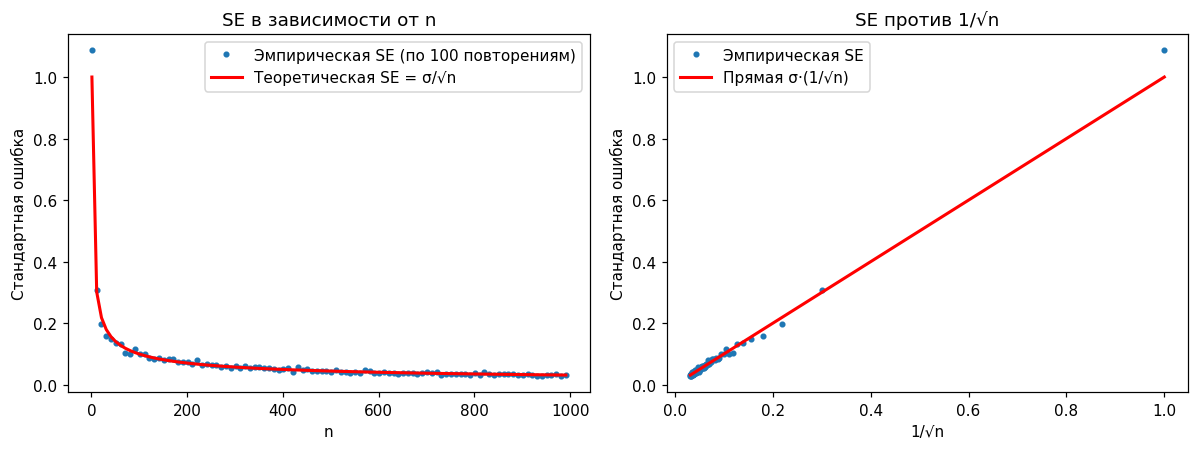

Наклон прямой SE = k / sqrt(n), МНК без свободного члена: k = 1.0533 (теория: σ = 1.0)
n =    1: SE эмп. = 1.0869, σ/√n = 1.0000
n =  101: SE эмп. = 0.0998, σ/√n = 0.0995
n =  501: SE эмп. = 0.0433, σ/√n = 0.0447
n =  991: SE эмп. = 0.0333, σ/√n = 0.0318


In [9]:
se_emp = np.array([my_std(means[:, j]) for j in range(len(ns))])
se_th = SIGMA / np.sqrt(ns)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].plot(ns, se_emp, 'o', ms=3, label='Эмпирическая SE (по 100 повторениям)')
axes[0].plot(ns, se_th, 'r-', lw=2, label='Теоретическая SE = σ/√n')
axes[0].set_xlabel('n'); axes[0].set_ylabel('Стандартная ошибка')
axes[0].set_title('SE в зависимости от n'); axes[0].legend()

axes[1].plot(1/np.sqrt(ns), se_emp, 'o', ms=3, label='Эмпирическая SE')
axes[1].plot(1/np.sqrt(ns), se_th, 'r-', lw=2, label='Прямая σ·(1/√n)')
axes[1].set_xlabel('1/√n'); axes[1].set_ylabel('Стандартная ошибка')
axes[1].set_title('SE против 1/√n'); axes[1].legend()
plt.tight_layout()
plt.savefig('fig4_se.png', dpi=130)
plt.show()

slope = np.sum((1/np.sqrt(ns)) * se_emp) / np.sum((1/np.sqrt(ns))**2)
print(f'Наклон прямой SE = k / sqrt(n), МНК без свободного члена: k = {slope:.4f} (теория: σ = {SIGMA})')
for n_check in [1, 101, 501, 991]:
    j = list(ns).index(n_check)
    print(f'n = {n_check:>4}: SE эмп. = {se_emp[j]:.4f}, σ/√n = {se_th[j]:.4f}')

**Вывод о сходимости.** При малых n траектории разбросаны широко (при n = 1 среднее — это одно значение экспоненциальной величины, оно может быть и 0.05, и 4). С ростом n все траектории стягиваются к μ = 1, а коридор разброса сужается пропорционально 1/√n. Эмпирическая стандартная ошибка совпадает с σ/√n, наклон зависимости SE от 1/√n близок к σ = 1. Это и есть закон больших чисел: выборочное среднее сходится по вероятности к математическому ожиданию.

Скорость сходимости медленная: чтобы уменьшить ошибку в 10 раз, нужно увеличить выборку в 100 раз.

## 6. Выводы

1. **Собственные функции** для среднего, дисперсии, стандартного отклонения, медианы, квартилей, асимметрии и эксцесса реализованы через `np.sum` и `np.sort` и совпадают с `numpy`/`scipy` с точностью до ошибок округления (порядка 1e-15). Для совпадения важно учитывать два соглашения: дисперсия в numpy по умолчанию смещённая (`ddof=0`), а scipy в асимметрии и эксцессе делит на смещённое σ.

2. **Эмпирические статистики согласуются с теоретическими.** Для выборок объёма 500 среднее, дисперсия, медиана и квартили отличаются от теории на единицы процентов. Асимметрия и эксцесс отличаются сильнее, особенно эксцесс экспоненциального распределения: моменты высоких порядков чувствительны к редким большим значениям в хвосте, и для их точной оценки нужны выборки гораздо большего объёма.

3. **Графики** подтверждают совпадение формы: гистограмма экспоненциальной выборки повторяет кривую $e^{-x}$, относительные частоты Пуассона близки к $P(X=k)$.

4. **Влияние объёма выборки.** Разброс выборочного среднего уменьшается как σ/√n: это видно и по сужению коридора траекторий, и по линейной зависимости стандартной ошибки от 1/√n. Точность растёт медленно, в 10 раз меньшая ошибка требует в 100 раз большей выборки.

5. **Закон больших чисел** выполняется: все 100 траекторий выборочного среднего при росте n сходятся к математическому ожиданию μ = 1, хотя исходное распределение сильно асимметрично.